# 2장 4강: 이벤트 로그 기반 AARRR 퍼널 집계 및 시각화 — 실습문제

## 실습 목표

- 계정·구독·기능 사용 데이터를 연결하여 퍼널 단계 도달 기록을 만들 수 있다.
- `groupby()`와 `nunique()`로 단계별 고유 계정 수를 집계할 수 있다.
- 전 단계 대비 전환율과 최초 단계 대비 전체 전환율을 계산할 수 있다.
- 퍼널을 가로 막대그래프로 시각화하고 이탈 집중 구간을 찾을 수 있다.
- 수치에서 확인한 이탈 구간을 바탕으로 개선 가설과 검증 방법을 제안할 수 있다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- `ravenstack_accounts.csv`
- `ravenstack_subscriptions.csv`
- `ravenstack_feature_usage.csv`

Ravenstack은 구독형 B2B SaaS입니다. 이번 실습에서는 다음 네 단계를 누적 퍼널로 정의합니다.

| 단계 | 도달 조건 |
|---|---|
| Acquisition | 관찰 종료일보다 30일 이상 앞서 가입한 계정 |
| Activation | 가입 후 30일 이내 첫 구독을 시작한 계정 |
| Retention | Activation 계정 중 첫 구독 시작 30일 후에도 유효한 기능 사용 기록이 있는 계정 |
| Revenue | Retention 계정 중 첫 구독이 체험판이 아니고 `mrr_amount > 0`인 계정 |

> Ravenstack 데이터에는 다른 사용자를 추천한 행동을 뜻하는 Referral 이벤트가 없습니다. `referral_source`는 **현재 계정이 유입된 경로**이므로 Referral 행동으로 잘못 사용하지 않고, 이번 실습에서는 측정 가능한 Acquisition~Revenue 4단계만 분석합니다.

## 실습 준비

1. 필요한 라이브러리를 불러오세요.
2. 세 CSV 파일을 각각 `accounts`, `subscriptions`, `feature_usage`에 불러오세요.
3. 각 데이터의 행과 열 개수, 상위 5개 행을 확인하세요.
4. 분석 대상 컬럼의 자료형과 결측치를 확인하세요.
5. 날짜 컬럼을 날짜형으로 변환하세요.
6. 계정별 가장 이른 구독을 `first_subscription`으로 만드세요.
7. 기능 사용 기록에 첫 구독 정보를 결합하고, 구독 시작 전 또는 종료 후 기록을 제외한 `valid_usage`를 만드세요.
8. 기능 사용 데이터의 마지막 날짜에서 30일을 뺀 날짜를 `observation_cutoff`으로 정하세요.

> 가입 직후 30일이 지나지 않은 계정은 Retention 도달 기회가 부족하므로 분석 대상에서 제외합니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정
for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in {f.name for f in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False

# 1~2. 데이터 불러오기
accounts = pd.read_csv('ravenstack_accounts.csv')
subscriptions = pd.read_csv('ravenstack_subscriptions.csv')
feature_usage = pd.read_csv('ravenstack_feature_usage.csv')

# 3. 크기와 상위 5행
for name, df in [('accounts', accounts), ('subscriptions', subscriptions), ('feature_usage', feature_usage)]:
    print(f'{name}: {df.shape}')
    display(df.head())

# 4. 분석 대상 컬럼의 자료형과 결측치
check = {
    'accounts': ['account_id', 'signup_date'],
    'subscriptions': ['subscription_id', 'account_id', 'start_date', 'end_date', 'plan_tier', 'is_trial', 'mrr_amount'],
    'feature_usage': ['usage_id', 'subscription_id', 'usage_date'],
}
for name, cols in check.items():
    df = globals()[name]
    print(f'▶ {name}')
    display(pd.DataFrame({'dtype': df[cols].dtypes, 'null_count': df[cols].isna().sum()}))

# 5. 날짜형 변환
accounts['signup_date'] = pd.to_datetime(accounts['signup_date'])
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'])
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'])

# 6. 계정별 가장 이른 구독 (시작일이 같으면 subscription_id 순으로 1건만)
first_subscription = (subscriptions.sort_values(['account_id', 'start_date', 'subscription_id'])
                      .drop_duplicates('account_id', keep='first')
                      [['account_id', 'subscription_id', 'start_date', 'end_date', 'plan_tier', 'is_trial', 'mrr_amount']]
                      .rename(columns={'subscription_id': 'first_sub_id', 'start_date': 'first_start',
                                       'end_date': 'first_end', 'plan_tier': 'first_plan',
                                       'is_trial': 'first_is_trial', 'mrr_amount': 'first_mrr'}))
print('first_subscription:', first_subscription.shape, '| 계정 수:', first_subscription['account_id'].nunique())

# 7. 기능 사용 기록 + 첫 구독 정보 결합 → 첫 구독 기간 안의 기록만 유효
usage_first = feature_usage.merge(first_subscription, left_on='subscription_id', right_on='first_sub_id', how='inner')
in_period = (usage_first['usage_date'] >= usage_first['first_start']) & (
    usage_first['first_end'].isna() | (usage_first['usage_date'] <= usage_first['first_end']))
valid_usage = usage_first[in_period].copy()
print(f'첫 구독에 연결된 사용 기록: {len(usage_first):,}건 → 유효 기록: {len(valid_usage):,}건 '
      f'(시작 전 {(usage_first["usage_date"] < usage_first["first_start"]).sum():,}건, '
      f'종료 후 {(usage_first["first_end"].notna() & (usage_first["usage_date"] > usage_first["first_end"])).sum():,}건 제외)')

# 8. 관찰 기준일
observation_end = feature_usage['usage_date'].max()
observation_cutoff = observation_end - pd.Timedelta(days=30)
print('관찰 종료일:', observation_end.date(), '| observation_cutoff:', observation_cutoff.date())

accounts: (500, 10)


,account_id,account_name,industry,country,signup_date,referral_source,plan_tier,seats,is_trial,churn_flag
0,A-2e4581,Company_0,EdTech,US,2024-10-16,partner,Basic,9,False,False
1,A-43a9e3,Company_1,FinTech,IN,2023-08-17,other,Basic,18,False,True
2,A-0a282f,Company_2,DevTools,US,2024-08-27,organic,Basic,1,False,False
3,A-1f0ac7,Company_3,HealthTech,UK,2023-08-27,other,Basic,24,True,False
4,A-ce550d,Company_4,HealthTech,US,2024-10-27,event,Enterprise,35,False,True


subscriptions: (5000, 14)


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True


feature_usage: (25000, 8)


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False
2,U-096807,S-f29e7f,2023-12-07,feature_3,9,1458,0,False
3,U-6b1580,S-be655e,2024-07-28,feature_40,5,2085,0,False
4,U-720a29,S-f9b1d0,2024-12-02,feature_12,12,900,0,False


... (3 outputs left out)

,dtype,null_count
subscription_id,str,0
account_id,str,0
start_date,str,0
end_date,str,4514
plan_tier,str,0
is_trial,bool,0
mrr_amount,int64,0


▶ feature_usage


,dtype,null_count
usage_id,str,0
subscription_id,str,0
usage_date,str,0


first_subscription: (500, 7) | 계정 수: 500
첫 구독에 연결된 사용 기록: 2,472건 → 유효 기록: 958건 (시작 전 1,467건, 종료 후 47건 제외)
관찰 종료일: 2024-12-31 | observation_cutoff: 2024-12-01


> **준비 단계 메모**
> - `first_subscription`은 계정별 가장 이른 `start_date`를 가진 구독 1건입니다(500개 계정). 시작일이 같으면 `subscription_id` 순으로 1건만 남겼습니다.
> - `valid_usage`는 요구사항대로 **첫 구독에 속한 기능 사용 기록** 중 첫 구독 기간(시작일~종료일) 안의 기록만 남긴 것입니다. 첫 구독에 연결된 2,472건 중 958건만 유효합니다.
> - `observation_cutoff` = 2024-12-31 − 30일 = **2024-12-01**이고, 이 날 이전에 가입한 483개 계정이 분석 대상입니다.
> - `accounts`에도 `plan_tier`, `is_trial` 컬럼이 있어서, 이름이 겹치지 않도록 첫 구독 컬럼은 `first_plan`, `first_is_trial` 등으로 바꿨습니다(과제 1은 **첫 구독의** 요금제 기준).

---

## 필수 1. AARR 단계별 고유 계정 수와 전환율 계산하기

### 문제 1-1. 가입한 계정은 활성화·유지·유료 단계까지 얼마나 도달하는가?

#### 문제 해결 방향

각 단계의 조건을 만족하는 계정 ID를 만들고, 앞 단계에 도달한 계정만 다음 단계에 포함되도록 누적 조건을 적용하세요. 그다음 긴 형태의 `funnel_log`를 만들어 강의에서 배운 `groupby()`와 `nunique()`로 집계합니다.

#### 요구사항

1. `signup_date <= observation_cutoff`인 계정을 `funnel_base`로 만드세요.
2. Acquisition, Activation, Retention, Revenue 도달 여부를 불리언 컬럼으로 만드세요.
3. 단계별 도달 계정만 모아 `account_id`, `stage`로 구성된 `funnel_log`를 만드세요.
4. `groupby("stage")["account_id"].nunique()`로 고유 계정 수를 집계하세요.
5. `reindex()`를 사용해 `Acquisition → Activation → Retention → Revenue` 순서로 정렬하세요.
6. `calc_conversion_rates()` 함수를 작성하여 전 단계 대비 전환율과 전체 대비 전환율을 계산하세요.
7. 단계별 고유 계정 수와 두 전환율을 하나의 `funnel_summary`로 출력하세요.

#### 해석 질문

**Q1.** 이벤트 발생 횟수 대신 고유 계정 수를 사용하는 이유는 무엇인가요?  
**Q2.** 첫 단계의 전 단계 대비 전환율을 100%로 설정하는 이유는 무엇인가요?  
**Q3.** Retention 단계에 이전 단계 조건을 함께 적용해야 하는 이유는 무엇인가요?  
**Q4.** 전 단계 대비 전환율과 전체 대비 전환율은 무엇이 다른가요?

#### 제출 결과

- `funnel_base`와 `funnel_log`
- `calc_conversion_rates()` 함수
- `funnel_summary`
- Q1~Q4 답변

In [2]:
STAGES = ['Acquisition', 'Activation', 'Retention', 'Revenue']

def build_funnel_base(accounts, first_subscription, valid_usage, cutoff):
    """계정별 AARR 단계 도달 여부(누적 조건)를 만든다."""
    base = accounts.loc[accounts['signup_date'] <= cutoff, ['account_id', 'signup_date']].merge(
        first_subscription, on='account_id', how='left')

    # Acquisition: 관찰 기준일 이전 가입
    base['Acquisition'] = True
    # Activation: 가입 후 0~30일 안에 첫 구독 시작
    days_to_sub = (base['first_start'] - base['signup_date']).dt.days
    base['Activation'] = base['Acquisition'] & days_to_sub.between(0, 30)
    # Retention: 첫 구독 시작 30일 후에도 유효 기능 사용 기록 존재
    retained_ids = valid_usage.loc[valid_usage['usage_date'] >= valid_usage['first_start'] + pd.Timedelta(days=30),
                                   'account_id'].unique()
    base['Retention'] = base['Activation'] & base['account_id'].isin(retained_ids)
    # Revenue: 첫 구독이 체험판이 아니고 MRR > 0
    base['Revenue'] = base['Retention'] & (base['first_is_trial'] == False) & (base['first_mrr'] > 0)
    return base

# 1~2. funnel_base
funnel_base = build_funnel_base(accounts, first_subscription, valid_usage, observation_cutoff)
print('funnel_base:', funnel_base.shape)
display(funnel_base[['account_id', 'signup_date', 'first_start', 'first_plan'] + STAGES].head())

# 3. 긴 형태의 funnel_log (도달한 단계만)
funnel_log = (funnel_base.melt(id_vars='account_id', value_vars=STAGES, var_name='stage', value_name='reached')
              .query('reached')[['account_id', 'stage']].reset_index(drop=True))
print('funnel_log:', funnel_log.shape)
display(funnel_log.head())

# 4~5. 단계별 고유 계정 수
stage_counts = funnel_log.groupby('stage')['account_id'].nunique().reindex(STAGES, fill_value=0)

# 6. 전환율 함수
def calc_conversion_rates(counts):
    """전 단계 대비 전환율(첫 단계=100%)과 최초 단계 대비 전체 전환율을 계산한다."""
    counts = counts.astype(float)
    step = counts / counts.shift(1)
    step.iloc[0] = 1.0
    overall = counts / counts.iloc[0]
    return pd.DataFrame({'accounts': counts.astype(int), 'step_conversion': step, 'overall_conversion': overall})

# 7. funnel_summary
funnel_summary = calc_conversion_rates(stage_counts)
display(funnel_summary.style.format({'step_conversion': '{:.1%}', 'overall_conversion': '{:.1%}'}))

funnel_base: (483, 12)


,account_id,signup_date,first_start,first_plan,Acquisition,Activation,Retention,Revenue
0,A-2e4581,2024-10-16,2024-10-20,Pro,True,True,True,True
1,A-43a9e3,2023-08-17,2023-09-20,Basic,True,False,False,False
2,A-0a282f,2024-08-27,2024-08-31,Enterprise,True,True,False,False
3,A-1f0ac7,2023-08-27,2023-12-04,Pro,True,False,False,False
4,A-ce550d,2024-10-27,2024-10-28,Enterprise,True,True,True,True


funnel_log: (1188, 2)


,account_id,stage
0,A-2e4581,Acquisition
1,A-43a9e3,Acquisition
2,A-0a282f,Acquisition
3,A-1f0ac7,Acquisition
4,A-ce550d,Acquisition


,accounts,step_conversion,overall_conversion
stage,,,
Acquisition,483,100.0%,100.0%
Activation,321,66.5%,66.5%
Retention,207,64.5%,42.9%
Revenue,177,85.5%,36.6%


### 필수 1 답변 작성란

**funnel_summary**: Acquisition 483 → Activation 321 (전 단계 대비 66.5%) → Retention 207 (64.5%, 전체 대비 42.9%) → Revenue 177 (85.5%, 전체 대비 36.6%)

- **Q1.** 이벤트 횟수는 "얼마나 자주 했는가"를 세기 때문에, 한 계정이 기능을 100번 쓰면 100으로 잡혀 단계 규모가 부풀려집니다. 퍼널은 "몇 개의 계정이 이 단계에 **도달**했는가"를 보는 도구이므로, 한 계정을 한 번만 세는 고유 계정 수(`nunique`)를 써야 단계끼리 비교할 수 있고 전환율이 100%를 넘는 일도 생기지 않습니다.
- **Q2.** 첫 단계는 비교할 이전 단계가 없고, 퍼널의 기준(분모) 자체이기 때문입니다. "이 단계에 들어온 전원이 출발점"이라는 의미로 100%로 둡니다. 이렇게 하면 전 단계 대비 전환율을 곱해 나가면 전체 대비 전환율이 되는 관계도 유지됩니다(0.665 × 0.645 ≈ 0.429).
- **Q3.** 누적 퍼널은 각 단계가 이전 단계의 부분집합이어야 전환율이 의미를 가집니다. 이전 조건 없이 "30일 후 사용 기록"만 보면, 가입 30일 이후에 늦게 구독한 계정처럼 **Activation을 거치지 않은 계정**까지 Retention에 들어갑니다. 그러면 Retention이 부풀려지고, 전 단계 대비 전환율이 실제 "활성화된 계정 중 유지된 비율"을 뜻하지 않게 됩니다.
- **Q4.** 전 단계 대비 전환율은 **바로 앞 단계를 통과한 계정 중** 이 단계까지 온 비율로, 어느 구간에서 병목이 생기는지 찾을 때 씁니다(예: Retention 64.5%). 전체 대비 전환율은 **최초 단계(Acquisition) 대비** 누적 도달률로, 전체 여정의 효율을 보여줍니다(예: Retention 42.9%). 전체 대비 전환율은 단계가 내려갈수록 줄어들기만 하지만, 전 단계 대비 전환율은 단계마다 오르내릴 수 있습니다.

---

## 필수 2. 퍼널 시각화와 이탈 구간 개선 가설 만들기

### 문제 2-1. 가장 먼저 개선해야 할 구간은 어디인가?

#### 요구사항

1. 필수 1의 `funnel_summary`를 사용하세요.
2. `barh()`로 단계별 고유 계정 수를 가로 막대그래프로 표시하세요.
3. 막대 옆에 `계정 수 (전 단계 대비 전환율)`을 표시하세요.
4. 첫 단계를 제외하고 전 단계 대비 전환율이 가장 낮은 단계를 찾으세요.
5. 해당 단계와 바로 이전 단계를 이용해 전환율이 가장 낮은 구간을 출력하세요.
6. 이탈 원인 가설 2개와 각 가설의 검증 방법을 제안하세요.

#### 해석 질문

**Q1.** 전 단계 대비 전환율이 가장 낮은 단계와 이탈 구간은 어디인가요?  
**Q2.** 퍼널 결과만으로 이탈의 원인을 확정할 수 있나요?  
**Q3.** 해당 구간을 개선하기 위해 어떤 데이터를 추가로 확인할 수 있나요?

#### 제출 결과

- 전환율을 표시한 퍼널 그래프
- 가장 낮은 전환 단계와 이탈 구간
- 개선 가설 2개와 검증 방법
- Q1~Q3 답변

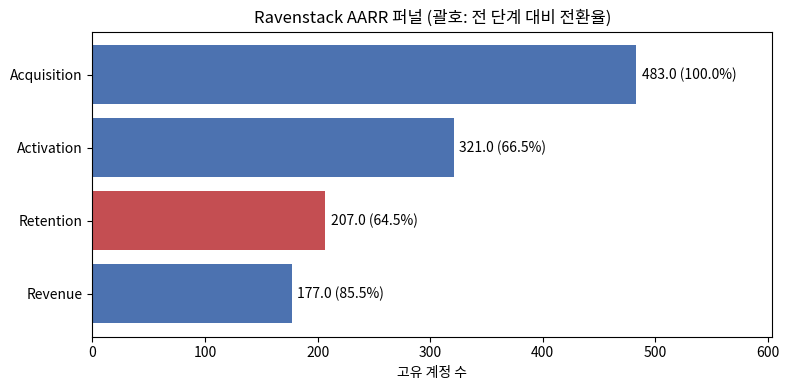

전환율 최저 단계: Retention
이탈 구간: Activation → Retention | 전환율 64.5%, 이탈률 35.5%, 이탈 114개 계정

구간별 전환율:
  Acquisition → Activation: 66.5% (이탈 162개)
  Activation → Retention: 64.5% (이탈 114개)
  Retention → Revenue: 85.5% (이탈 30개)

▶ Activation 계정의 유지 여부별 비교 (평균)


,early_usage_rows,early_features,early_errors,first_sub_days
Retention,,,,
False,0.24,0.24,0.04,124.68
True,0.15,0.15,0.06,322.41


첫 30일 유효 사용이 0건인 비율:


Retention
False    79.8%
True     85.5%
Name: early_usage_rows, dtype: str

첫 구독이 30일 안에 종료된 비율 / 첫 구독 유효 사용이 전혀 없는 비율:


,ended_within_30d,no_valid_usage
Retention,,
False,0.044,0.798
True,0.000,0.000


Retention 미도달 114개 중 다른 구독 포함 시 30일 후 사용 기록이 있는 계정: 83개 (72.8%)
Retention 미도달 계정의 평균 구독 건수: 10.0건


In [3]:
# 2~3. 가로 막대 퍼널
fs = funnel_summary.iloc[::-1]   # 위에서부터 Acquisition이 오도록 뒤집기
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#C44E52' if s == funnel_summary['step_conversion'].iloc[1:].idxmin() else '#4C72B0' for s in fs.index]
bars = ax.barh(fs.index, fs['accounts'], color=colors)
for b, (stage, r) in zip(bars, fs.iterrows()):
    ax.text(b.get_width() + 5, b.get_y() + b.get_height() / 2,
            f"{r['accounts']:,} ({r['step_conversion']:.1%})", va='center', fontsize=10)
ax.set_xlim(0, funnel_summary['accounts'].max() * 1.25)
ax.set_xlabel('고유 계정 수')
ax.set_title('Ravenstack AARR 퍼널 (괄호: 전 단계 대비 전환율)')
plt.tight_layout(); plt.show()

# 4~5. 전환율이 가장 낮은 단계와 구간
steps = funnel_summary.iloc[1:]
worst_stage = steps['step_conversion'].idxmin()
prev_stage = STAGES[STAGES.index(worst_stage) - 1]
w = funnel_summary.loc[worst_stage]
dropped = int(funnel_summary.loc[prev_stage, 'accounts'] - w['accounts'])
print(f'전환율 최저 단계: {worst_stage}')
print(f'이탈 구간: {prev_stage} → {worst_stage} | 전환율 {w["step_conversion"]:.1%}, '
      f'이탈률 {1 - w["step_conversion"]:.1%}, 이탈 {dropped}개 계정')

# (참고) 두 번째로 낮은 구간과의 차이
print('\n구간별 전환율:')
for s in steps.index:
    p = STAGES[STAGES.index(s) - 1]
    print(f'  {p} → {s}: {funnel_summary.loc[s, "step_conversion"]:.1%} '
          f'(이탈 {funnel_summary.loc[p, "accounts"] - funnel_summary.loc[s, "accounts"]}개)')

# 가설 검증을 위한 탐색: Activation 계정 중 유지/이탈 그룹의 첫 30일 사용 행태 비교
act = funnel_base[funnel_base['Activation']].copy()
early = valid_usage[valid_usage['usage_date'] < valid_usage['first_start'] + pd.Timedelta(days=30)]
early_agg = early.groupby('account_id').agg(early_usage_rows=('usage_id', 'size'),
                                            early_features=('feature_name', 'nunique'),
                                            early_errors=('error_count', 'sum'))
act = act.merge(early_agg, on='account_id', how='left').fillna({'early_usage_rows': 0, 'early_features': 0, 'early_errors': 0})
act['first_sub_days'] = (act['first_end'].fillna(observation_end) - act['first_start']).dt.days
print('\n▶ Activation 계정의 유지 여부별 비교 (평균)')
display(act.groupby('Retention')[['early_usage_rows', 'early_features', 'early_errors', 'first_sub_days']].mean().round(2))
print('첫 30일 유효 사용이 0건인 비율:')
display(act.groupby('Retention')['early_usage_rows'].apply(lambda x: (x == 0).mean()).map('{:.1%}'.format))
act['ended_within_30d'] = act['first_end'].notna() & (act['first_sub_days'] < 30)
act['usage_rows_total'] = act['account_id'].map(valid_usage.groupby('account_id').size()).fillna(0)
print('첫 구독이 30일 안에 종료된 비율 / 첫 구독 유효 사용이 전혀 없는 비율:')
display(act.groupby('Retention').agg(ended_within_30d=('ended_within_30d', 'mean'),
                                     no_valid_usage=('usage_rows_total', lambda x: (x == 0).mean())).round(3))

# 가설 2 확인: 첫 구독 외 '다른 구독'에서는 사용했는가? (측정 정의가 이탈을 과대 계상하는지)
all_usage = feature_usage.merge(subscriptions[['subscription_id', 'account_id', 'start_date', 'end_date']], on='subscription_id')
all_valid = all_usage[(all_usage['usage_date'] >= all_usage['start_date']) &
                      (all_usage['end_date'].isna() | (all_usage['usage_date'] <= all_usage['end_date']))]
all_valid = all_valid.merge(first_subscription[['account_id', 'first_start']], on='account_id')
later_ids = all_valid.loc[all_valid['usage_date'] >= all_valid['first_start'] + pd.Timedelta(days=30), 'account_id'].unique()
lost = act[~act['Retention']]
n_sub = subscriptions.groupby('account_id').size()
print(f"Retention 미도달 {len(lost)}개 중 다른 구독 포함 시 30일 후 사용 기록이 있는 계정: "
      f"{lost['account_id'].isin(later_ids).sum()}개 ({lost['account_id'].isin(later_ids).mean():.1%})")
print(f"Retention 미도달 계정의 평균 구독 건수: {lost['account_id'].map(n_sub).mean():.1f}건")

### 필수 2 답변 작성란

**가장 낮은 전환 단계**: `Retention` → 이탈 구간 **Activation → Retention** (전환율 64.5%, 이탈률 35.5%, 이탈 114개 계정)

참고로 Acquisition → Activation도 66.5%로 거의 비슷하게 낮고, 이탈 계정 수로는 이 구간이 162개로 더 많습니다. 전환율 기준 최저 구간은 Retention이지만, 두 구간 모두 개선 후보로 보는 것이 좋습니다.

**이탈 원인 가설 2개와 검증 방법**

| # | 가설 | 탐색 결과(노트북 코드) | 검증 방법 |
|---|---|---|---|
| 1 | **구독은 시작했지만 제품을 실제로 쓰기 시작하지 않았다(온보딩 실패).** 구독 후 초기 설정이나 첫 핵심 기능 사용까지 이어지지 않아, 30일 뒤에도 사용 기록이 남지 않는다. | Retention 미도달 계정의 **79.8%는 첫 구독 기간 동안 유효 사용 기록이 한 건도 없음** | 구독 후 첫 사용까지 걸린 시간, 온보딩 단계별 완료율 로그를 수집하고, 유지·미유지 그룹을 비교합니다. 그다음 가이드형 온보딩(체크리스트·첫 과제 템플릿)을 A/B 테스트해 **30일 후 사용 계정 비율**을 비교합니다. |
| 2 | **실제 이탈이 아니라 측정 정의 때문에 이탈로 잡혔다.** 계정이 첫 구독을 짧게 끝내고 다른 구독(업그레이드·재계약)으로 옮겨가서 사용했는데, "첫 구독의 사용 기록"만 보니 이탈로 분류됐을 수 있다. | 미도달 114개 중 **83개(72.8%)는 다른 구독까지 포함하면 30일 후 사용 기록이 있음.** 미도달 계정의 첫 구독 유지 기간은 평균 125일로, 유지 계정(322일)보다 짧음 | 구독 전환 이력(`upgrade_flag`/`downgrade_flag`, 구독 간 간격)을 확인하고, **계정 단위** Retention 정의(모든 구독 합산)로 퍼널을 다시 계산해 두 정의의 전환율 차이를 비교합니다. 차이가 크면 지표 정의부터 바로잡아야 합니다. |

- **Q1.** 전 단계 대비 전환율이 가장 낮은 단계는 **Retention(64.5%)**이고, 이탈 구간은 **Activation → Retention**입니다(114개 계정 이탈).
- **Q2.** 확정할 수 없습니다. 퍼널은 "어디서" 빠지는지만 보여줍니다. 가설 2의 탐색에서 보듯, 이탈처럼 보이는 수치가 **측정 정의 때문에 생긴 착시**일 수도 있습니다. 원인은 추가 데이터와 실험으로 검증해야 합니다.
- **Q3.** 다음 데이터를 추가로 확인할 수 있습니다.
  - 구독 후 첫 기능 사용까지 걸린 시간, 온보딩 이벤트 로그
  - 첫 30일간 사용한 기능 종류·사용 시간·`error_count`
  - 구독 전환 이력(업그레이드·다운그레이드·재계약)
  - 좌석 수 대비 실제 사용자 수
  - 지원 티켓·이탈 사유(`churn_events`)
  - 계정 속성(산업·유입 채널)별 Retention

---

## 과제 1. 평가 문항 기반 독립 과제

### 문제 3-1. 첫 구독 요금제별 퍼널 비교와 개선 가설 제안하기

#### 문제 설명

첫 구독의 plan_tier별로 Acquisition → Activation → Retention → Revenue 단계의 계정 수와 전환율을 비교하세요. 이탈이 집중된 구간을 찾고, 개선 가설과 검증 방법을 제안하세요.

> 필수 문제의 단계 정의와 집계·전환율 계산·시각화 절차를 그대로 활용합니다. Referral은 관련 행동 기록이 없어 분석에서 제외합니다.

#### 요구사항

1. 원시 계정·구독·기능 사용 데이터를 연결하여 funnel_base와 단계 도달 여부를 만드는 코드를 제출물에 포함하세요. 필수 문제에서 작성한 코드를 재사용해도 됩니다.
2. 첫 구독의 plan_tier별로 Acquisition, Activation, Retention, Revenue의 고유 계정 수를 집계하세요. 각 단계에는 이전 단계에 도달한 계정만 포함하세요.
3. 요금제별로 다음 값을 계산하여 plan_funnel을 만드세요.
- 구간 전환율 = 현재 단계 계정 수 ÷ 이전 단계 계정 수 × 100
- 구간 이탈률 = 100 − 구간 전환율
- 구간 이탈 계정 수 = 이전 단계 계정 수 − 현재 단계 계정 수
- 첫 단계는 비교할 이전 단계가 없으므로 구간 지표를 빈 값으로 두세요. 이전 단계 계정 수가 0이면 전환율·이탈률을 계산 불가로 표시하세요.
4. 요금제별로 단계별 고유 계정 수를 가로 막대그래프로 시각화하고, 각 단계의 구간 전환율을 함께 표시하세요.
5. 첫 단계를 제외하고 전환율이 가장 낮은 요금제·구간 조합을 찾으세요. 해당 구간의 전환율·이탈률·이탈 계정 수를 근거로 이탈 집중 구간을 설명하세요.
6. 요금제별 최종 Revenue 도달률을 계산하여 plan_summary로 출력하세요. 가장 높은 요금제와 낮은 요금제의 차이를 %p로 계산하세요.
- 최종 Revenue 도달률 = Revenue 계정 수 ÷ Acquisition 계정 수 × 100
7. 우선 점검할 구간에 대해 “어떤 원인 때문에 이탈하며, 어떤 변경을 하면 전환율이 개선될 것이다”라는 개선 가설을 한 가지 작성하세요.
8. 가설을 확인하기 위한 추가 데이터 2가지와 검증 방법을 설명하세요. 어떤 대상을 비교하고 어떤 지표로 개선 여부를 판단할지 포함하세요. 실제 실험이나 통계 검정은 수행하지 않아도 됩니다.

#### 해석 질문

Q1. 전환율이 가장 낮은 요금제와 구간은 무엇이며, 전환율·이탈률·이탈 계정 수는 얼마인가요?

Q2. 최종 Revenue 도달률이 가장 높은 요금제와 낮은 요금제는 무엇이며, 차이는 몇 %p인가요?

Q3. 우선 점검할 구간에 대한 개선 가설은 무엇이며, 어떤 데이터와 방법으로 검증할 수 있나요?

Q4. 요금제별 차이만으로 요금제가 이탈의 원인이라고 결론 내릴 수 있나요?

#### 제출 결과

- 원시 데이터 연결 및 단계 도달 여부 구성 코드
- plan_funnel: 단계별 계정 수·전환율·이탈률·이탈 계정 수
- 요금제별 퍼널 그래프
- 이탈 집중 구간과 수치 근거
- plan_summary: 최종 Revenue 도달률과 최고·최저 차이
- 개선 가설·추가 확인 데이터 2가지·검증 방법
- Q1~Q4 답변

,plan_tier,stage,accounts,prev_accounts,conversion_rate,drop_rate,dropped_accounts,note
0,Basic,Acquisition,161,,,,,첫 단계
1,Basic,Activation,101,161,62.7,37.3,60,
2,Basic,Retention,70,101,69.3,30.7,31,
3,Basic,Revenue,58,70,82.9,17.1,12,
4,Pro,Acquisition,159,,,,,첫 단계
5,Pro,Activation,101,159,63.5,36.5,58,
6,Pro,Retention,66,101,65.3,34.7,35,
7,Pro,Revenue,59,66,89.4,10.6,7,
8,Enterprise,Acquisition,163,,,,,첫 단계
9,Enterprise,Activation,119,163,73.0,27.0,44,


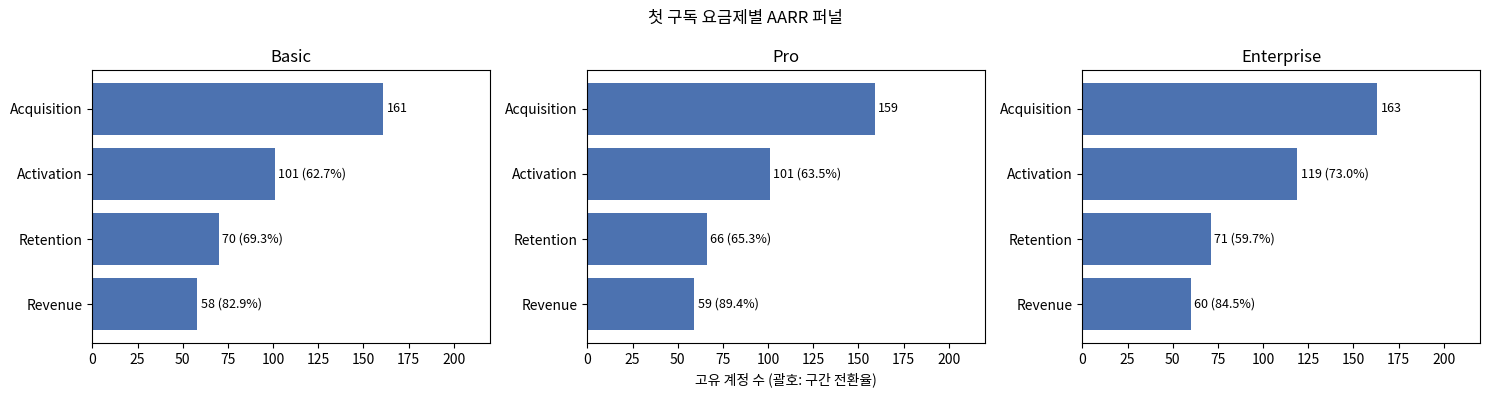

최저 조합: Enterprise / Activation → Retention — 전환율 59.7%, 이탈률 40.3%, 이탈 48개 계정

▶ 구간 × 요금제 전환율(%)


plan_tier,Basic,Pro,Enterprise
transition,,,
Acquisition → Activation,62.7,63.5,73.0
Activation → Retention,69.3,65.3,59.7
Retention → Revenue,82.9,89.4,84.5


,acquisition,revenue,revenue_reach_rate
plan_tier,,,
Pro,159,59,37.11
Enterprise,163,60,36.81
Basic,161,58,36.02


최고 Pro 37.11% vs 최저 Basic 36.02% → 차이 1.09%p

▶ Enterprise Activation 계정: 유지 여부별 평균


,seats,early_usage_rows,early_features,first_sub_days
Retention,,,,
False,20.60,0.21,0.21,122.21
True,22.27,0.13,0.13,321.48


In [4]:
# 1. 원시 데이터 연결 + 단계 도달 여부 (필수 1의 함수 재사용)
funnel_base = build_funnel_base(accounts, first_subscription, valid_usage, observation_cutoff)
plans = ['Basic', 'Pro', 'Enterprise']

# 2~3. 요금제별 고유 계정 수와 구간 지표
def calc_segment_funnel(base, segment_col, value):
    seg = base[base[segment_col] == value]
    log = (seg.melt(id_vars='account_id', value_vars=STAGES, var_name='stage', value_name='reached')
              .query('reached'))
    counts = log.groupby('stage')['account_id'].nunique().reindex(STAGES, fill_value=0)
    out = pd.DataFrame({'plan_tier': value, 'stage': STAGES, 'accounts': counts.values})
    prev = out['accounts'].shift(1)
    out['prev_accounts'] = prev
    out['conversion_rate'] = np.where(prev > 0, out['accounts'] / prev * 100, np.nan)
    out['drop_rate'] = 100 - out['conversion_rate']
    out['dropped_accounts'] = prev - out['accounts']
    out['note'] = np.where(prev.isna(), '첫 단계', np.where(prev == 0, '계산 불가', ''))
    return out

plan_funnel = pd.concat([calc_segment_funnel(funnel_base, 'first_plan', p) for p in plans], ignore_index=True)
display(plan_funnel.style.format({'prev_accounts': '{:.0f}', 'conversion_rate': '{:.1f}', 'drop_rate': '{:.1f}',
                                  'dropped_accounts': '{:.0f}'}, na_rep=''))

# 4. 요금제별 가로 막대 퍼널
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, p in zip(axes, plans):
    d = plan_funnel[plan_funnel['plan_tier'] == p].iloc[::-1]
    bars = ax.barh(d['stage'], d['accounts'], color='#4C72B0')
    for b, (_, r) in zip(bars, d.iterrows()):
        label = f"{r['accounts']}" + ('' if pd.isna(r['conversion_rate']) else f" ({r['conversion_rate']:.1f}%)")
        ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, label, va='center', fontsize=9)
    ax.set_title(f'{p}'); ax.set_xlim(0, plan_funnel['accounts'].max() * 1.35)
axes[1].set_xlabel('고유 계정 수 (괄호: 구간 전환율)')
fig.suptitle('첫 구독 요금제별 AARR 퍼널')
plt.tight_layout(); plt.show()

# 5. 전환율이 가장 낮은 요금제 × 구간
steps_p = plan_funnel.dropna(subset=['conversion_rate']).copy()
steps_p['transition'] = steps_p['stage'].map(lambda s: f"{STAGES[STAGES.index(s) - 1]} → {s}")
wp = steps_p.loc[steps_p['conversion_rate'].idxmin()]
print(f"최저 조합: {wp['plan_tier']} / {wp['transition']} — 전환율 {wp['conversion_rate']:.1f}%, "
      f"이탈률 {wp['drop_rate']:.1f}%, 이탈 {wp['dropped_accounts']:.0f}개 계정")
print('\n▶ 구간 × 요금제 전환율(%)')
display(steps_p.pivot(index='transition', columns='plan_tier', values='conversion_rate')
        .reindex(columns=plans).loc[[f"{STAGES[i-1]} → {STAGES[i]}" for i in range(1, 4)]].round(1))

# 6. plan_summary: 최종 Revenue 도달률
acq = plan_funnel[plan_funnel['stage'] == 'Acquisition'].set_index('plan_tier')['accounts']
rev = plan_funnel[plan_funnel['stage'] == 'Revenue'].set_index('plan_tier')['accounts']
plan_summary = pd.DataFrame({'acquisition': acq, 'revenue': rev})
plan_summary['revenue_reach_rate'] = (plan_summary['revenue'] / plan_summary['acquisition'] * 100).round(2)
plan_summary = plan_summary.loc[plans].sort_values('revenue_reach_rate', ascending=False)
display(plan_summary)
gap = plan_summary['revenue_reach_rate'].max() - plan_summary['revenue_reach_rate'].min()
print(f"최고 {plan_summary.index[0]} {plan_summary['revenue_reach_rate'].iloc[0]:.2f}% vs "
      f"최저 {plan_summary.index[-1]} {plan_summary['revenue_reach_rate'].iloc[-1]:.2f}% → 차이 {gap:.2f}%p")

# 7~8 참고: 최저 조합(Enterprise Activation 계정)의 첫 30일 사용 행태 · 좌석 수 비교
ent_act = act[act['first_plan'] == wp['plan_tier']].merge(accounts[['account_id', 'seats']], on='account_id', how='left')
print(f"\n▶ {wp['plan_tier']} Activation 계정: 유지 여부별 평균")
display(ent_act.groupby('Retention')[['seats', 'early_usage_rows', 'early_features', 'first_sub_days']].mean().round(2))

### 과제 1 답변 작성란

**plan_funnel 요약 (구간 전환율 %)**

| 구간 | Basic | Pro | Enterprise |
|---|---|---|---|
| Acquisition → Activation | 62.7 | 63.5 | **73.0** |
| Activation → Retention | 69.3 | 65.3 | **59.7** ← 최저 |
| Retention → Revenue | 82.9 | 89.4 | 84.5 |

**이탈 집중 구간**: **Enterprise × Activation → Retention**입니다. 활성화된 119개 계정 중 71개만 유지되어 전환율 59.7%, 이탈률 40.3%, 이탈 48개 계정입니다. 모든 요금제·구간 조합 중 전환율이 가장 낮고, 이탈 계정 수도 이 구간에서 가장 많습니다. Enterprise는 활성화율(73.0%)이 가장 높은데 유지 구간에서 가장 크게 빠져서, 두 효과가 서로 상쇄됩니다.

**plan_summary (최종 Revenue 도달률)**: Pro 37.11% > Enterprise 36.81% > Basic 36.02%이고, 최고와 최저의 차이는 **1.09%p**입니다.

**개선 가설**: *Enterprise 계정은 좌석 수가 많고 여러 부서가 도입 과정에 관여하는데, 구독 후 30일 안에 실무 사용자에게 사용이 퍼지지 않아서(도입 담당자만 설정하고 팀 사용이 시작되지 않아서) 유지 단계에서 이탈한다. 구독 직후 전담 CSM이 팀 단위 온보딩 세션과 사용자 초대 캠페인을 진행하면, Activation → Retention 전환율이 개선될 것이다.*

**추가 확인 데이터 2가지와 검증 방법**

1. **첫 30일 사용자 확산 데이터**: 좌석 수 대비 실제 활성 사용자 수, 초대된 사용자 수, 첫 사용까지 걸린 일수. Enterprise Activation 계정을 유지 그룹과 미유지 그룹으로 나눠 비교해서, 미유지 그룹의 좌석 활성화 비율이 뚜렷이 낮은지 확인합니다.
2. **구독 전환·계약 이력**: 첫 구독 이후의 업그레이드·재계약 여부와 구독 간 간격. 필수 2의 가설 2처럼 "다른 구독으로 옮겨가 사용한 계정"이 이탈로 잡혔는지 확인하고, 계정 단위로 다시 정의한 Retention으로도 Enterprise가 여전히 가장 낮은지 봅니다.

**검증 방법**: 새로 활성화되는 Enterprise 계정을 무작위로 두 그룹으로 나눕니다. 처리군에는 팀 온보딩과 CSM을, 대조군에는 기존 온보딩을 제공합니다. 주요 지표는 **구독 30일 후 유효 사용 계정 비율(Activation → Retention 전환율)**이고, 보조 지표는 좌석 활성화율, 가드레일 지표는 CSM 투입 비용과 Revenue 전환율입니다. Enterprise는 표본이 작으므로 필요한 표본 수를 미리 계산하고 충분한 기간 동안 운영합니다.

- **Q1.** **Enterprise × Activation → Retention**입니다. 전환율 **59.7%**, 이탈률 **40.3%**, 이탈 계정 **48개**(119 → 71)입니다.
- **Q2.** 가장 높은 요금제는 **Pro (37.11%)**, 가장 낮은 요금제는 **Basic (36.02%)**이고, 차이는 **1.09%p**입니다. 요금제별로 병목 구간은 다르지만(Basic·Pro는 Activation, Enterprise는 Retention), 최종 도달률은 거의 같습니다.
- **Q3.** 가설은 "Enterprise는 구독 후 30일 안에 팀 사용이 퍼지지 않아 유지 단계에서 이탈하므로, 팀 단위 온보딩과 CSM 지원을 제공하면 전환율이 오를 것"입니다. 검증에는 ① 좌석 대비 활성 사용자·초대 데이터, ② 구독 전환·계약 이력을 쓰고, 신규 Enterprise 계정 대상 A/B 테스트에서 30일 후 유효 사용 계정 비율을 비교합니다.
- **Q4.** 결론 내릴 수 없습니다. 이유는 다음과 같습니다.
  - 요금제별 표본이 약 160개(Enterprise Activation 119개)로 작아서, 몇 개 계정 차이로도 전환율이 수 %p씩 움직입니다.
  - 요금제는 고객이 스스로 고른 속성이라 조직 규모·산업·도입 목적 같은 교란 변수와 얽혀 있습니다.
  - "첫 구독 사용 기록" 기준이라, 다른 구독으로 옮겨간 계정이 이탈로 잡히는 측정 한계가 있습니다.
  - 최종 Revenue 도달률 차이도 1.09%p에 불과합니다.
  
  요금제 차이는 점검 우선순위를 정하는 근거일 뿐이고, 원인은 통제 분석이나 실험으로 확인해야 합니다.

---

## 실습 마무리

1. 이번 분석에서는 각 AARR 단계를 어떤 조건으로 정의했나요?
2. 단계별 고유 계정 수는 어떤 코드로 집계했나요?
3. 전 단계 대비 전환율과 전체 대비 전환율은 각각 무엇을 보여주나요?
4. 어느 구간에서 이탈이 가장 집중되었나요?
5. 퍼널 수치와 이탈 원인을 왜 구분해야 하나요?
6. Referral 단계를 이번 분석에서 제외한 이유는 무엇인가요?

### 실습 마무리 답변

1. **단계 정의**
   - Acquisition: `observation_cutoff`(2024-12-01) 이전에 가입한 계정
   - Activation: 가입 후 0~30일 안에 첫 구독을 시작한 계정
   - Retention: Activation 계정 중 첫 구독 시작 30일 후에도 첫 구독 기간 안에 유효 기능 사용 기록이 있는 계정
   - Revenue: Retention 계정 중 첫 구독이 체험판이 아니고 `mrr_amount > 0`인 계정
   
   모든 단계는 이전 단계 조건을 누적해서 적용했습니다.
2. **집계 코드**: 도달 여부를 `melt()`로 긴 형태의 `funnel_log`(account_id, stage)로 바꾼 뒤 `funnel_log.groupby("stage")["account_id"].nunique().reindex(STAGES)`로 집계했습니다.
3. **두 전환율의 차이**: 전 단계 대비 전환율은 구간별 병목(어느 단계에서 막히는지)을 보여주고, 전체 대비 전환율은 최초 유입 대비 누적 도달 효율(가입 계정 중 최종 유료까지 간 비율 36.6%)을 보여줍니다.
4. **이탈이 가장 집중된 구간**: 전환율 기준으로는 **Activation → Retention (64.5%)**입니다. 이탈 계정 수로는 Acquisition → Activation(162개)이 더 많아서 두 구간이 모두 핵심 병목입니다. 요금제별로는 Enterprise의 Activation → Retention(59.7%)이 가장 낮았습니다.
5. **수치와 원인을 구분해야 하는 이유**: 퍼널 수치는 "어디서" 빠지는지만 보여줍니다. 이번에도 Retention 미도달 계정의 72.8%가 다른 구독에서는 계속 사용하고 있어서, 수치상 이탈 중 상당 부분이 **측정 정의 때문일 수 있음**을 확인했습니다. 원인을 단정하면 잘못된 개선에 자원을 쓰게 되므로, 가설 → 추가 데이터 → 실험 순서로 검증해야 합니다.
6. **Referral을 제외한 이유**: Referral은 "기존 고객이 다른 고객을 추천하는 행동"인데, 데이터에 그런 추천 행동 이벤트가 없습니다. `referral_source`는 **이 계정이 어떤 경로로 들어왔는지**를 나타내는 Acquisition 속성이라, 이를 Referral 단계로 쓰면 지표의 의미가 왜곡됩니다. 측정할 수 없는 단계는 억지로 만들지 않고 제외했습니다.